# Newton法はなぜ2次収束するのか

## 概要

Newton法は、接線と横軸の交点を次の近似解に使う反復法である。単純根の近くでは誤差の1次の項が消え、2次の項が残る。本記事ではこの関係をTaylor展開から導き、$x^2-2=0$で確認する。重根、初期値、丸め誤差によって何が変わるかも扱う。

## 実行環境

仮想環境は `wa-src(3.14.6)`、Pythonは `3.14.6` である。リポジトリの `.venv` を使う同名のJupyterカーネルを選び、上から実行する。使用ライブラリとOSは下の出力に示す。

計算は途中で丸めず、表示する小数だけを有効数字3桁にする。グラフは実行ディレクトリの `101_nb_files` にSVGで保存し、出力欄にもSVGで表示する。

In [1]:
import platform
import sys
from decimal import Decimal, getcontext
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
set_matplotlib_formats("svg")

assert platform.python_version() == "3.14.6"
assert sys.prefix != sys.base_prefix
print("環境名: wa-src(3.14.6)")
print("Python:", platform.python_version())
print("OS:", platform.platform())
print("実行ファイル:", sys.executable)
pprint({name: version(name) for name in ("numpy", "matplotlib", "sympy")})

# 誤差の評価には120桁の十進演算を使う。グラフ用の配列だけfloatに変換する。
getcontext().prec = 120
np.set_printoptions(formatter={"float_kind": lambda value: f"{value:.2e}"})
figure_dir = Path("101_nb_files")
figure_dir.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "svg.fonttype": "none"})


def tick_label(value, position):
    """整数はそのまま、小数は末尾の0を含む有効数字3桁で表示する。"""
    if float(value).is_integer() and abs(value) < 1000:
        return str(int(value))
    return f"{value:#.3g}"


def save_figure(fig, name):
    """軸の表示を整え、同じ図をSVGファイルと出力欄に保存する。"""
    for ax in fig.axes:
        if ax.get_xscale() == "linear":
            ax.xaxis.set_major_formatter(FuncFormatter(tick_label))
        if ax.get_yscale() == "linear":
            ax.yaxis.set_major_formatter(FuncFormatter(tick_label))
        ax.grid(True, alpha=0.250)
    fig.tight_layout()
    fig.savefig(figure_dir / name, format="svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

環境名: wa-src(3.14.6)
Python: 3.14.6
OS: macOS-26.5.2-arm64-arm-64bit-Mach-O
実行ファイル: /Users/hiroshi/private/wa_src/.venv/bin/python
{'matplotlib': '3.11.2', 'numpy': '2.5.4', 'sympy': '1.14.0'}


## 1. 接線から更新式を作る

解を$\alpha$、近似解を$x_n$とし、$f(\alpha)=0$とする。$x_n$での接線を$q_n(x)$と置く。$f'(x_n)\ne0$なら、接線の零点は次のように求まる。

$$
\displaystyle
\begin{aligned}
q_n(x)&=f(x_n)+f'(x_n)(x-x_n),\\
0&=f(x_n)+f'(x_n)(x_{n+1}-x_n),\\
f'(x_n)(x_{n+1}-x_n)&=-f(x_n),\\
x_{n+1}&=x_n-\frac{f(x_n)}{f'(x_n)}.
\end{aligned}
$$

以下の関数は収束の観察用で、指定回数の履歴を返す。関数値が0なら終了し、導関数が0なら例外にする。実用時には反復回数に加え、更新量と残差を用いた停止判定も必要である。図1は$x_0=2$からの最初の2回の更新である。

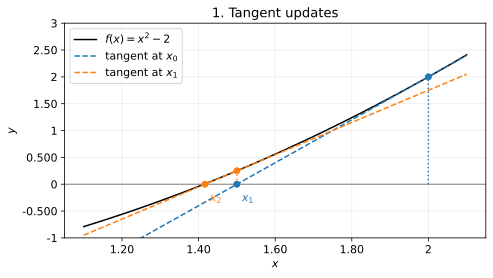

In [2]:
def newton_history(f, df, x0, steps):
    """floatとDecimalのどちらでも使える、固定回数のNewton反復。"""
    x = x0
    values = [x]
    for _ in range(steps):
        fx = f(x)
        if fx == 0:
            break
        slope = df(x)
        if slope == 0:
            raise ZeroDivisionError("導関数が0のため更新できない")
        x = x - fx / slope
        values.append(x)
    return values


def f(x):
    return x**2 - 2


def df(x):
    return 2 * x


xs_float = newton_history(f, df, 2.00, 7)
grid = np.linspace(1.10, 2.10, 400)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, f(grid), color="black", label=r"$f(x)=x^2-2$")
ax.axhline(0, color="gray", linewidth=1)
for n, color in enumerate(("tab:blue", "tab:orange")):
    xn, xn_next = xs_float[n:n + 2]
    ax.plot(grid, f(xn) + df(xn) * (grid - xn), "--",
            color=color, label=rf"tangent at $x_{n}$")
    ax.plot([xn, xn], [0, f(xn)], ":", color=color)
    ax.scatter([xn, xn_next], [f(xn), 0], color=color, zorder=3)
    ax.annotate(rf"$x_{n + 1}$", (xn_next, 0), xytext=(5, -18),
                textcoords="offset points", color=color)
ax.set(xlabel="$x$", ylabel="$y$", ylim=(-1, 3), title="1. Tangent updates")
ax.legend()
save_figure(fig, "01_tangents.svg")

## 2. 誤差の1次の項が消える

$f$は$\alpha$の近傍で2回連続微分可能、$f'(\alpha)\ne0$とする。このような根を単純根という。誤差を$e_n=x_n-\alpha$と置き、$x_n$を中心に$\alpha$までTaylor展開する。$\xi_n$は$x_n$と$\alpha$の間の点である。

$$
\displaystyle
\begin{aligned}
0=f(\alpha)
&=f(x_n)+f'(x_n)(\alpha-x_n)
 +\frac{f''(\xi_n)}{2}(\alpha-x_n)^2\\
&=f(x_n)-f'(x_n)e_n+\frac{f''(\xi_n)}{2}e_n^2,\\
f(x_n)&=f'(x_n)e_n-\frac{f''(\xi_n)}{2}e_n^2,\\
\frac{f(x_n)}{f'(x_n)}&=e_n-\frac{f''(\xi_n)}{2f'(x_n)}e_n^2.
\end{aligned}
$$

これを更新式に代入する。

$$
\displaystyle
\begin{aligned}
e_{n+1}&=x_{n+1}-\alpha\\
&=x_n-\alpha-\frac{f(x_n)}{f'(x_n)}\\
&=e_n-\left(e_n-\frac{f''(\xi_n)}{2f'(x_n)}e_n^2\right)\\
&=\frac{f''(\xi_n)}{2f'(x_n)}e_n^2.
\end{aligned}
$$

引き算によって$e_n$が消えることが、2次収束の理由である。私は速度の名称より、この相殺を確認する方が理解しやすいと感じる。

### 近くから始める条件

十分小さい閉区間で$|f'(x)|\ge m>0$、$|f''(x)|\le M$とし、正の定数$K\ge M/(2m)$を取る。半径$\delta$をこの区間内で$K\delta\le1/2$となるように選ぶと、$|e_0|\le\delta$から

$$
\displaystyle |e_{n+1}|\le K|e_n|^2\le\frac12|e_n|\le\delta
$$

が帰納的に成り立つ。反復点は区間内にとどまり、$e_n\to0$となる。したがって、収束を初めから仮定する必要はない。

$f''(\alpha)\ne0$で、有限回で解に到達しない場合には、次の極限が正となり、収束次数はちょうど2である。

$$
\displaystyle
\lim_{n\to\infty}\frac{|e_{n+1}|}{|e_n|^2}
=\left|\frac{f''(\alpha)}{2f'(\alpha)}\right|=C>0.
$$

$f''(\alpha)=0$なら2次より速い収束や有限回での終了もあり得る。「少なくとも2次」と「ちょうど2次」は区別する。

## 3. 平方根で数値を確認する

$f(x)=x^2-2$、$\alpha=\sqrt2$では、誤差の式を直接整理できる。

$$
\displaystyle
\begin{aligned}
x_{n+1}&=x_n-\frac{x_n^2-2}{2x_n}
=\frac{x_n^2+2}{2x_n},\\
e_{n+1}&=\frac{x_n^2+2-2\alpha x_n}{2x_n}
=\frac{x_n^2+\alpha^2-2\alpha x_n}{2x_n}\\
&=\frac{(x_n-\alpha)^2}{2x_n}
=\frac{e_n^2}{2x_n},\\
C&=\frac{1}{2\sqrt2}\approx0.354.
\end{aligned}
$$

SymPyでもこの恒等式を確認する。数式の出力には `display()` を使う。

In [3]:
x = sp.symbols("x", positive=True)
alpha_symbol = sp.sqrt(2)
next_error = x - (x**2 - 2) / (2 * x) - alpha_symbol
expected = (x - alpha_symbol)**2 / (2 * x)
assert sp.simplify(next_error - expected) == 0
display(Math(r"x-\frac{x^2-2}{2x}-\sqrt{2}=" + sp.latex(expected)))
display(Math(r"C=\frac{1}{2\sqrt{2}}\approx0.354"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 高精度計算と通常の浮動小数点計算

120桁の `Decimal` で$\sqrt2$と誤差を計算する。通常の `float` の誤差も、この基準値との差で評価する。`float` 同士で差を取ると、基準値の丸めによって誤差を0と誤認することがある。

図2では高精度計算の誤差が急減する一方、`float` は$10^{-16}$程度で停滞する。ここでの2次収束は厳密演算の性質であり、計算機で無限に続くものではない。

[{'n': 0, 'x_n': '2.00E+0', 'abs_error': '5.86E-1'},
 {'n': 1, 'x_n': '1.50E+0', 'abs_error': '8.58E-2'},
 {'n': 2, 'x_n': '1.42E+0', 'abs_error': '2.45E-3'},
 {'n': 3, 'x_n': '1.41E+0', 'abs_error': '2.12E-6'},
 {'n': 4, 'x_n': '1.41E+0', 'abs_error': '1.59E-12'},
 {'n': 5, 'x_n': '1.41E+0', 'abs_error': '8.99E-25'},
 {'n': 6, 'x_n': '1.41E+0', 'abs_error': '2.86E-49'},
 {'n': 7, 'x_n': '1.41E+0', 'abs_error': '2.89E-98'}]


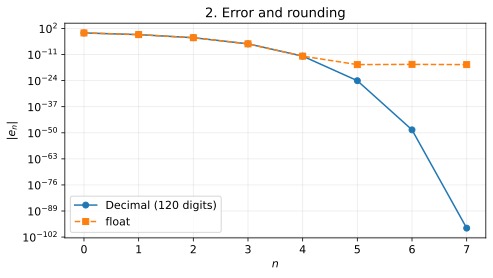

In [4]:
alpha = Decimal(2).sqrt()
xs = newton_history(f, df, Decimal(2), 7)
errors = [abs(xn - alpha) for xn in xs]
float_errors = [abs(Decimal.from_float(xn) - alpha) for xn in xs_float]
ratios = [errors[n + 1] / errors[n]**2 for n in range(len(errors) - 1)]

# 小数の表示は科学表記に統一する。表はリストなのでpprintを使う。
rows = []
for n, (xn, error) in enumerate(zip(xs, errors)):
    rows.append({"n": n, "x_n": f"{xn:.2E}", "abs_error": f"{error:.2E}"})
pprint(rows, sort_dicts=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(range(len(errors)), [float(e) for e in errors], "o-", label="Decimal (120 digits)")
ax.semilogy(range(len(float_errors)), [float(e) for e in float_errors], "s--", label="float")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set(xlabel="$n$", ylabel=r"$|e_n|$", title="2. Error and rounding")
ax.legend()
save_figure(fig, "02_errors.svg")

### 誤差比と収束次数

図3では$|e_{n+1}|/|e_n|^2$が$0.354$へ近づく。図4は連続する誤差の両対数図であり、

$$
\displaystyle \log|e_{n+1}|\approx\log C+2\log|e_n|
$$

から傾き2が予想される。さらに、隣り合う対数誤差の差の比

$$
\displaystyle p_n=\frac{\log(|e_{n+1}|/|e_n|)}{\log(|e_n|/|e_{n-1}|)}
$$

も2へ近づく。近似解の表示が同じ値になっても、誤差の列を見れば改善を確認できる。

{'error_ratios': ['2.50E-1',
                  '3.33E-1',
                  '3.53E-1',
                  '3.54E-1',
                  '3.54E-1',
                  '3.54E-1',
                  '3.54E-1'],
 'estimated_orders': ['1.85E+0',
                      '1.98E+0',
                      '2.00E+0',
                      '2.00E+0',
                      '2.00E+0',
                      '2.00E+0']}


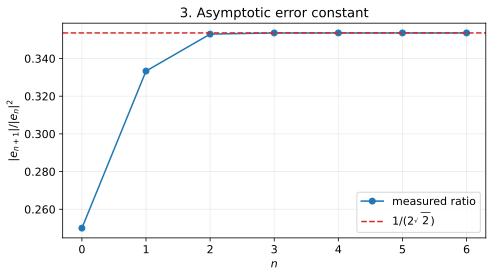

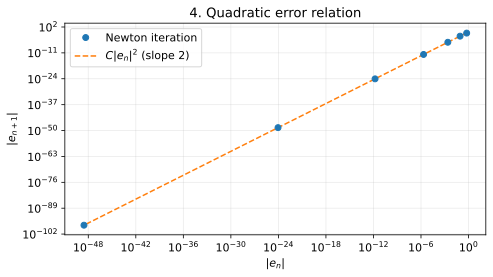

In [5]:
constant = 1 / (2 * alpha)
orders = [
    (errors[n + 1] / errors[n]).ln() / (errors[n] / errors[n - 1]).ln()
    for n in range(1, len(errors) - 1)
]
pprint({"error_ratios": [f"{r:.2E}" for r in ratios],
        "estimated_orders": [f"{p:.2E}" for p in orders]}, sort_dicts=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(len(ratios)), [float(r) for r in ratios], "o-", label="measured ratio")
ax.axhline(float(constant), color="tab:red", linestyle="--", label=r"$1/(2\sqrt{2})$")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set(xlabel="$n$", ylabel=r"$|e_{n+1}|/|e_n|^2$", title="3. Asymptotic error constant")
ax.legend()
save_figure(fig, "03_error_ratios.svg")

previous_errors = np.array([float(e) for e in errors[:-1]])
next_errors = np.array([float(e) for e in errors[1:]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(previous_errors, next_errors, "o", label="Newton iteration", zorder=3)
ax.loglog(previous_errors, float(constant) * previous_errors**2, "--", label=r"$C|e_n|^2$ (slope 2)")
ax.set(xlabel=r"$|e_n|$", ylabel=r"$|e_{n+1}|$", title="4. Quadratic error relation")
ax.legend()
save_figure(fig, "04_error_relation.svg")

## 4. 2次収束しない場合

### 重根では1次収束になる

$f(x)=(x-1)^2$では$f'(1)=0$となり、単純根の条件を満たさない。$x_n\ne1$なら

$$
\displaystyle
\begin{aligned}
x_{n+1}&=x_n-\frac{(x_n-1)^2}{2(x_n-1)}
=x_n-\frac{x_n-1}{2},\\
e_{n+1}&=x_n-1-\frac{x_n-1}{2}=\frac12e_n.
\end{aligned}
$$

誤差は毎回$0.500$倍になる。一般に$f(x)=(x-\alpha)^m$、整数$m\ge2$なら$e_{n+1}=(1-1/m)e_n$である。図5では重根の誤差が片対数図で直線になる。

{'multiple_root_ratios': ['5.00E-1',
                          '5.00E-1',
                          '5.00E-1',
                          '5.00E-1',
                          '5.00E-1',
                          '5.00E-1',
                          '5.00E-1']}


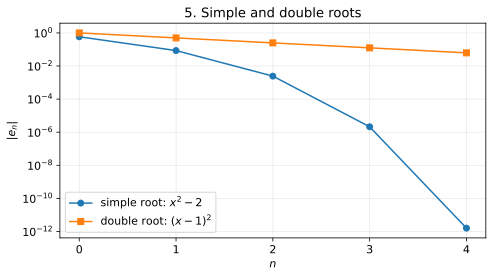

In [6]:
multiple_xs = newton_history(lambda x: (x - 1)**2, lambda x: 2 * (x - 1), Decimal(2), 7)
multiple_errors = [abs(xn - 1) for xn in multiple_xs]
pprint({"multiple_root_ratios": [
    f"{multiple_errors[n + 1] / multiple_errors[n]:.2E}"
    for n in range(len(multiple_errors) - 1)
]})

# 最初の5点を比較し、重根の直線的な減少を読み取りやすくする。
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(range(5), [float(e) for e in errors[:5]], "o-", label=r"simple root: $x^2-2$")
ax.semilogy(range(5), [float(e) for e in multiple_errors[:5]], "s-", label=r"double root: $(x-1)^2$")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set(xlabel="$n$", ylabel=r"$|e_n|$", title="5. Simple and double roots")
ax.legend()
save_figure(fig, "05_multiple_root.svg")

### 初期値によっては収束しない

$f(x)=x^3-2x+2$に対して$x_0=0$とすると、

$$
\displaystyle
x_1=0-\frac{2}{-2}=1,\qquad
x_2=1-\frac{1}{1}=0
$$

となり、0と1の往復が続く。図6はこの反復と、$x_0=-2$から根に近づく反復の比較である。導関数が0でなくても、初期値が根から遠ければ収束は保証されない。

{'x0=0': ['0', '1.00E+0', '0', '1.00E+0', '0', '1.00E+0', '0', '1.00E+0', '0'],
 'x0=-2, final': '-1.77E+0'}


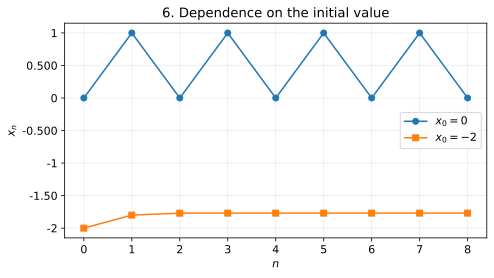

In [7]:
def cubic(x):
    return x**3 - 2 * x + 2


def cubic_derivative(x):
    return 3 * x**2 - 2


cycle = newton_history(cubic, cubic_derivative, Decimal(0), 8)
convergent = newton_history(cubic, cubic_derivative, Decimal(-2), 8)
pprint({"x0=0": [f"{xn:.2E}" if xn != 0 else "0" for xn in cycle],
        "x0=-2, final": f"{convergent[-1]:.2E}"}, sort_dicts=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(len(cycle)), [float(xn) for xn in cycle], "o-", label=r"$x_0=0$")
ax.plot(range(len(convergent)), [float(xn) for xn in convergent], "s-", label=r"$x_0=-2$")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set(xlabel="$n$", ylabel="$x_n$", title="6. Dependence on the initial value")
ax.legend()
save_figure(fig, "06_initial_values.svg")

## 結論

この記事では、Newton法で誤差の1次の項が相殺され、単純根の近傍で少なくとも2次収束することを示した。

$f''(\alpha)\ne0$なら漸近誤差定数は$|f''(\alpha)/(2f'(\alpha))|$である。平方根の計算で誤差比と収束次数を確認した。重根では収束が遅くなり、初期値によっては収束しない。数値実験では丸め誤差による停滞も区別する必要がある。

参考文献：T. A. Driscoll・R. J. Braun, [Fundamentals of Numerical Computation, 4.3 Newton’s method](https://fncbook.com/python/newton/)（更新式と誤差解析）。Stanford University, [Math 114: Newton’s method 3/3](https://web.stanford.edu/class/math114/decks/rootfinding/newtons_method3.html)（局所収束の条件）。